# IPCA – Decomposição Macroeconômica por Blocos

Este notebook utiliza a view **vw_groupsBySubItems** para decompor o IPCA
em blocos macroeconômicos consistentes com a literatura e com o Banco Central:

- Bens industriais
- Serviços
- Serviços subjacentes
- Monitorados
- Alimentação no domicílio
- Alimentação fora do domicílio

Objetivos:
- Construir séries mensais por bloco
- Construir séries acumuladas em 12 meses
- Criar dataset final para modelos estatísticos e ML

Este arquivo é compatível com Jupytext.

In [446]:
import os, sys
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if ROOT not in sys.path:
    sys.path.append(ROOT)

print("PYTHONPATH atualizado:", ROOT)

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import ccf
import dataframe_image as dfi

from src.database.connection import engine

pd.set_option("display.float_format", "{:.4f}".format)

PYTHONPATH atualizado: /home/moacir/projects/ml/analytics/inflation


# 1. Carregar dados da view `vw_groupsBySubItems`

Esta view já contém:
- grupos
- subgrupos
- itens
- subitens
- contribuições ponderadas
- IPCA cheio

Ela é a base ideal para decomposição macroeconômica.

In [234]:
query = """
SELECT
    date::date,
    "idGrupos",
    grupos,
    "idSubGrupos",
    "subGrupos",
    "idItens",
    itens,
    "ipcaItensCheio",
    "ipcaItensPorPeso",
    "idSubItens",
    "subItens",
    "ipcaSubItensCheio",
    "ipcaSubItensPorPeso"
FROM bcb."vw_groupsBySubItems"
ORDER BY date, "idSubItens";
"""

df = pd.read_sql(query, engine)
df["date"] = pd.to_datetime(df["date"])
df.head()

,date,idGrupos,grupos,idSubGrupos,subGrupos,idItens,itens,ipcaItensCheio,ipcaItensPorPeso,idSubItens,subItens,ipcaSubItensCheio,ipcaSubItensPorPeso
0,2020-01-01,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",0.7500,0.0052,1101002,Arroz,1.3100,0.0062
1,2020-01-01,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",0.7500,0.0052,1101051,Feijão - mulatinho,4.5000,0.0005
2,2020-01-01,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",0.7500,0.0052,1101052,Feijão - preto,-2.6800,-0.0013
3,2020-01-01,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",0.7500,0.0052,1101053,Feijão - macáçar (fradinho),5.3900,0.0007
4,2020-01-01,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",0.7500,0.0052,1101073,Feijão - carioca (rajado),-0.7000,-0.0009


# 2. Criar mapeamento de blocos macroeconômicos

Aqui definimos os blocos conforme a classificação tradicional do BC.
Ajuste conforme necessário.

In [235]:
map_blocos = {
    # Alimentação
    "Alimentação no domicílio": "Alimentação no domicílio",
    "Alimentação fora do domicílio": "Alimentação fora do domicílio",

    # Bens industriais
    "Aparelhos eletroeletrônicos": "Bens industriais",
    "Móveis e utensílios": "Bens industriais",
    "Roupas": "Bens industriais",
    "Calçados e acessórios": "Bens industriais",
    "Joias e bijuterias": "Bens industriais",
    "Tecidos e armarinho": "Bens industriais",

    # Serviços
    "Serviços pessoais": "Serviços",
    "Serviços de saúde": "Serviços",
    "Cuidados pessoais": "Serviços",
    "Consertos e manutenção": "Serviços",
    "Cursos, leitura e papelaria": "Serviços",
    "Recreação e fumo": "Serviços",

    # Monitorados
    "Combustíveis e energia": "Monitorados",
    "Transportes": "Monitorados",
    "Comunicação": "Monitorados",
    "Encargos e manutenção": "Monitorados",
    "Produtos farmacêuticos e óticos": "Monitorados",
}

# fallback
df["bloco_macro"] = df["subGrupos"].map(map_blocos).fillna("Outros")

df.head()

,date,idGrupos,grupos,idSubGrupos,subGrupos,idItens,itens,ipcaItensCheio,ipcaItensPorPeso,idSubItens,subItens,ipcaSubItensCheio,ipcaSubItensPorPeso,bloco_macro
0,2020-01-01,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",0.7500,0.0052,1101002,Arroz,1.3100,0.0062,Alimentação no domicílio
1,2020-01-01,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",0.7500,0.0052,1101051,Feijão - mulatinho,4.5000,0.0005,Alimentação no domicílio
2,2020-01-01,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",0.7500,0.0052,1101052,Feijão - preto,-2.6800,-0.0013,Alimentação no domicílio
3,2020-01-01,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",0.7500,0.0052,1101053,Feijão - macáçar (fradinho),5.3900,0.0007,Alimentação no domicílio
4,2020-01-01,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",0.7500,0.0052,1101073,Feijão - carioca (rajado),-0.7000,-0.0009,Alimentação no domicílio


In [116]:
df.groupby("bloco_macro")["ipcaSubItensCheio"].mean().reset_index()


,bloco_macro,ipcaSubItensCheio
0,Alimentação fora do domicílio,0.5192
1,Alimentação no domicílio,0.7280
2,Bens industriais,0.3819
3,Monitorados,0.4475
4,Serviços,0.4559


# 3. Contribuição mensal por bloco

Somamos a contribuição dos subitens dentro de cada bloco.

In [117]:
df_blocos = (
    df.groupby(["date", "bloco_macro"])["ipcaSubItensPorPeso"]
    .sum()
    .reset_index()
    .pivot(index="date", columns="bloco_macro", values="ipcaSubItensPorPeso")
)
df_blocos.reset_index()

bloco_macro,date,Alimentação fora do domicílio,Alimentação no domicílio,Bens industriais,Monitorados,Serviços
0,2020-01-01,0.0483,0.0268,-0.0252,0.1678,-0.0049
1,2020-02-01,0.0125,0.0086,-0.0365,-0.1134,0.3750
2,2020-03-01,0.0299,0.1877,-0.0315,-0.1770,0.0560
3,2020-04-01,0.0451,0.3054,-0.0478,-0.6312,0.0204
4,2020-05-01,0.0024,0.0455,-0.0079,-0.4434,0.0272
...,...,...,...,...,...,...
71,2025-12-01,0.0364,0.0219,0.0406,0.1321,0.0982
72,2026-01-01,0.0334,0.0157,-0.0067,0.1521,0.1314
73,2026-02-01,0.0205,0.0357,0.0098,0.2142,0.4204
74,2026-03-01,0.0375,0.2958,0.0351,0.3913,0.1155


# 4. Gráfico – Contribuição mensal por bloco

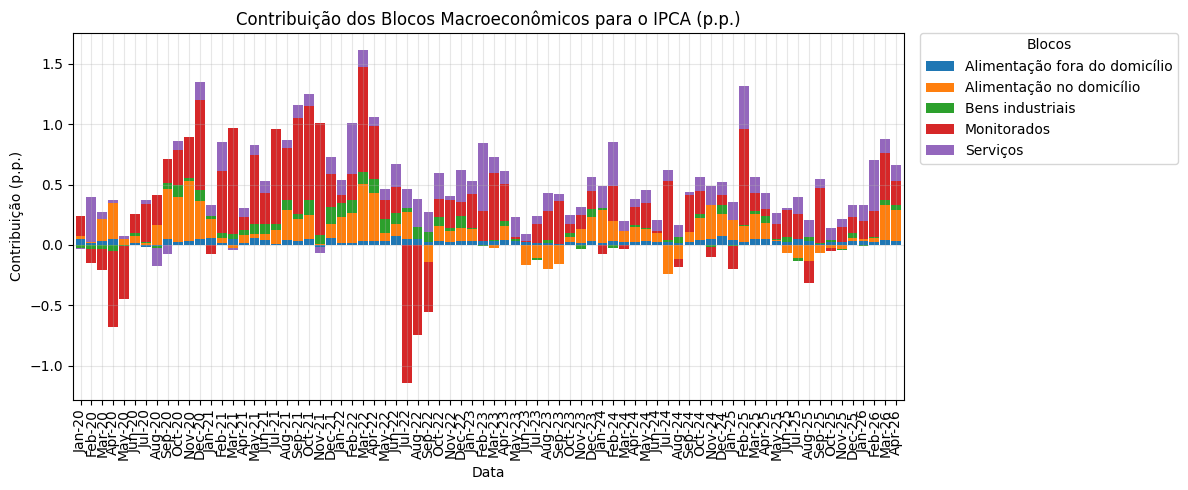

In [119]:
df_blocos_b = df_blocos.copy()
df_blocos_b.index = pd.to_datetime(df_blocos_b.index).strftime("%b-%y")

plt.figure(figsize=(12, 5))
df_blocos_b.plot(kind="bar", stacked=True, ax=plt.gca(), width=0.9)
plt.title("Contribuição dos Blocos Macroeconômicos para o IPCA (p.p.)")
plt.xlabel("Data")
plt.ylabel("Contribuição (p.p.)")
plt.grid(True, alpha=0.3)

# Legenda fora do gráfico, à direita
plt.legend(title="Blocos",
    bbox_to_anchor=(1.02, 1),   # desloca para fora
    loc="upper left",           # ancora no canto superior esquerdo da caixa
    borderaxespad=0)

plt.tight_layout()
plt.show()

## 4.1. Interpretação da Contribuição dos Blocos Macroeconômicos para o IPCA <br> (jan/2020 – abr/2026)

A decomposição do IPCA por blocos macroeconômicos permite identificar **quais grupos de preços puxaram a inflação para cima ou para baixo** ao longo do tempo. Cada barra representa o IPCA mensal, decomposto em:

- Alimentação no domicílio  
- Alimentação fora do domicílio  
- Bens industriais  
- Monitorados  
- Serviços  
- Outros (subgrupos não mapeados)

A seguir, a leitura econômica do período completo.

<br>

### 4.1.1. 2020 – Pré‑pandemia e início da crise
Nos primeiros meses (jan–fev/2020), o IPCA apresentava composição estável:

- Serviços e bens industriais eram os principais contribuintes.  
- Alimentação no domicílio tinha peso moderado.  

Esse padrão reflete um ambiente de inflação controlada, com dinâmica previsível.

<br>

### 4.1.2. 2020–2021 – Pandemia e choque de alimentos
A partir de mar/2020, a dinâmica muda abruptamente.

#### Alimentação no domicílio
Torna‑se o maior motor da inflação:

- choques climáticos,  
- câmbio depreciado,  
- problemas logísticos,  
- aumento da demanda doméstica.

Tubérculos, carnes, arroz e leite puxaram o bloco para cima de forma imediata.

#### Bens industriais
Também sobem:

- falta de insumos,  
- frete internacional caro,  
- estoques reduzidos.

Esse período explica a aceleração do IPCA mesmo com demanda fraca.

<br>

### 4.1.3. 2022–2023 – Monitorados dominam a inflação
O bloco de monitorados passa a ser o principal responsável pelas oscilações:

- combustíveis,  
- energia elétrica,  
- gás de cozinha,  
- tarifas reguladas.

A volatilidade do petróleo e mudanças tributárias geraram contribuições positivas e negativas expressivas.

<br>


### 4.1.4. 2023–2024 – Serviços ganham protagonismo
Com a reabertura da economia e o mercado de trabalho aquecido, serviços tornam‑se o bloco mais persistente:

- serviços pessoais,  
- saúde,  
- educação,  
- recreação,  
- cuidados pessoais.

Serviços são inerciais: sobem devagar, caem devagar.  
Isso sustenta o IPCA mesmo quando outros blocos aliviam.

<br>

### 4.1.5. 2024–2025 – Retorno da pressão de alimentos
O bloco de alimentação no domicílio volta a ganhar peso:

- tubérculos sobem rapidamente devido a choques climáticos,  
- hortifruti apresentam forte volatilidade,  
- itens processados repassam custos acumulados.

Ao mesmo tempo, alguns itens — como café moído — mostram deflação no atacado, mas só aparecem no IPCA meses depois devido a:

- estoques antigos comprados caro,  
- contratos de fornecimento,  
- cadeia longa,  
- repasse lento da queda.

Esse comportamento confirma a assimetria típica da inflação brasileira:  
**preços sobem rápido, mas caem devagar.**

<br>

### 4.1.6. 2025–2026 – Normalização gradual e recomposição dos blocos
Com a entrada dos dados de 2025 e início de 2026, o gráfico revela:

#### Serviços continuam como núcleo da inflação
- mercado de trabalho aquecido,  
- reajustes contratuais,  
- serviços pessoais e de saúde mantendo contribuição positiva.

#### Alimentação no domicílio perde força, mas segue volátil
- choques climáticos pontuais ainda geram picos,  
- mas a tendência é de normalização conforme safras se estabilizam.

#### Monitorados oscilam menos
- recomposição tributária concluída,  
- combustíveis menos voláteis,  
- energia elétrica com impacto mais moderado.

#### Bens industriais estabilizam
- câmbio menos pressionado,  
- cadeias globais normalizadas,  
- repasses mais suaves.

O período 2025–2026 mostra uma inflação mais “normal”, com menos choques extremos e maior peso dos componentes inerciais — especialmente serviços.

<br>

### 4.1.7. Conclusão geral
A decomposição por blocos revela que:

- Alimentação no domicílio é o componente mais volátil.  
- Monitorados geram movimentos bruscos ligados a combustíveis e tarifas.  
- Serviços são o núcleo inercial da inflação.  
- Bens industriais respondem ao câmbio e à logística.  
- A soma desses blocos explica a trajetória do IPCA desde 2020, marcada por choques sucessivos e repasses assimétricos.

Essa leitura é essencial para entender por que a inflação brasileira apresenta períodos de alta rápida e desaceleração lenta, especialmente em alimentos e serviços.

<br>

# 5. Séries agregadas por bloco (linha)

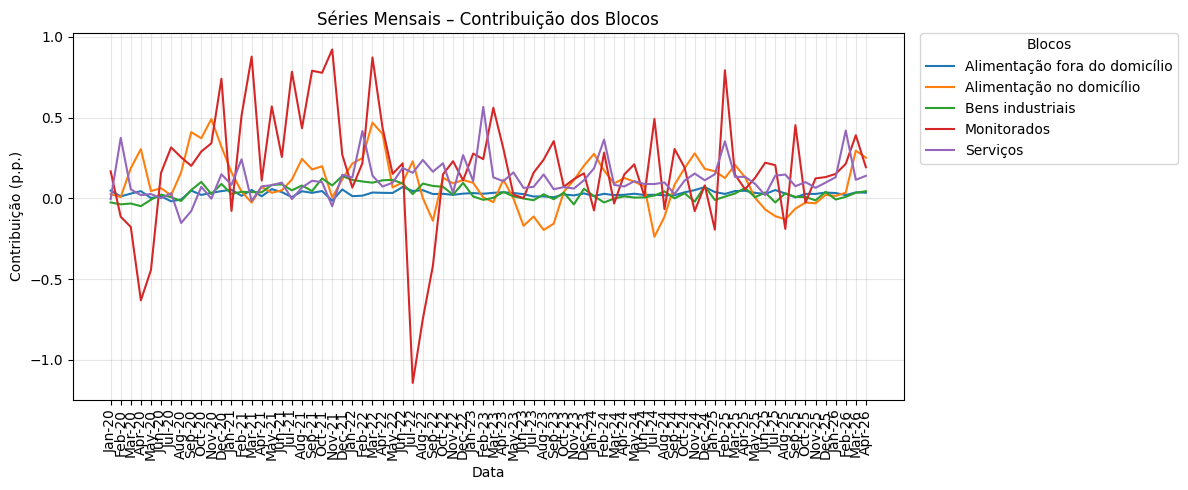

In [120]:
plt.figure(figsize=(12, 5))
for col in df_blocos_b.columns:
    plt.plot(df_blocos_b.index, df_blocos_b[col], label=col)

plt.title("Séries Mensais – Contribuição dos Blocos")
plt.xlabel("Data")
plt.ylabel("Contribuição (p.p.)")
plt.grid(True, alpha=0.3)
# Legenda fora do gráfico, à direita
plt.legend(title="Blocos", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tick_params(axis='x', rotation=90 )
plt.tight_layout()
plt.show()

# 6. Contribuição acumulada em 12 meses

Indicador fundamental para análise de tendência.

In [121]:
df_blocos_12m = df_blocos.rolling(12).sum()
df_blocos_12m.tail()

bloco_macro,Alimentação fora do domicílio,Alimentação no domicílio,Bens industriais,Monitorados,Serviços
date,,,,,
2025-12-01,0.4042,0.2324,0.1950,1.8559,1.5108
2026-01-01,0.3979,0.0795,0.1977,2.2012,1.4923
2026-02-01,0.3906,-0.0109,0.1963,1.6217,1.5588
2026-03-01,0.3822,0.0773,0.2008,1.8655,1.5412
2026-04-01,0.3705,0.1983,0.1809,2.0020,1.5473


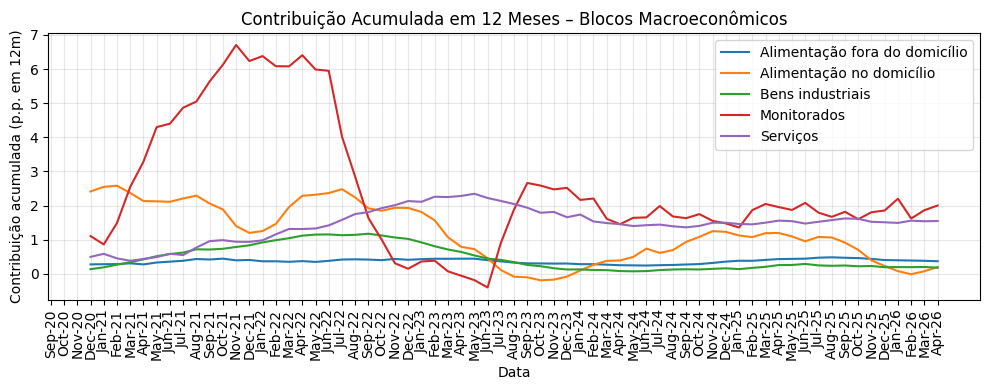

In [122]:
df_blocos_12m_b = df_blocos_12m.copy()
df_blocos_12m_b.index = pd.to_datetime(df_blocos_12m_b.index).strftime("%b-%y")

plt.figure(figsize=(10, 4))
for col in df_blocos_12m_b.columns:
    plt.plot(df_blocos_12m_b.index, df_blocos_12m_b[col], label=col)

plt.title("Contribuição Acumulada em 12 Meses – Blocos Macroeconômicos")
plt.xlabel("Data")
plt.ylabel("Contribuição acumulada (p.p. em 12m)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tick_params(axis='x', rotation=90 )
plt.tight_layout()
plt.show()

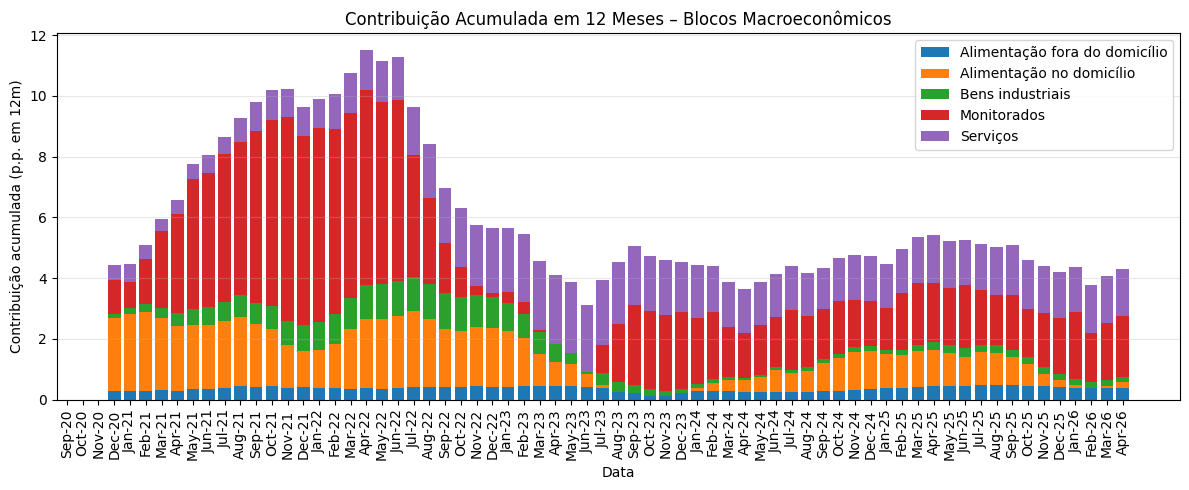

In [123]:
plt.figure(figsize=(12, 5))

# Inicializa o acumulador para empilhar as barras
bottom = np.zeros(len(df_blocos_12m_b))

for col in df_blocos_12m_b.columns:
    plt.bar(
        df_blocos_12m_b.index,
        df_blocos_12m_b[col],
        bottom=bottom,
        label=col
    )
    bottom += df_blocos_12m_b[col].values

plt.title("Contribuição Acumulada em 12 Meses – Blocos Macroeconômicos")
plt.xlabel("Data")
plt.ylabel("Contribuição acumulada (p.p. em 12m)")
plt.grid(True, axis="y", alpha=0.3)
plt.legend()
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


# 7. Dataset final para modelos estatísticos e ML

Inclui:
- contribuições mensais por bloco
- contribuições acumuladas em 12 meses
- pronto para regressões, VAR, ML etc.

In [51]:
df_ml = pd.concat(
    [
        df_blocos.add_prefix("bloco_"),
        df_blocos_12m.add_prefix("bloco_12m_"),
    ],
    axis=1,
)

df_ml.tail()

bloco_macro,bloco_Alimentação fora do domicílio,bloco_Alimentação no domicílio,bloco_Bens industriais,bloco_Monitorados,bloco_Serviços,bloco_12m_Alimentação fora do domicílio,bloco_12m_Alimentação no domicílio,bloco_12m_Bens industriais,bloco_12m_Monitorados,bloco_12m_Serviços
date,,,,,,,,,,
Dec-25,0.0364,0.0219,0.0406,0.1321,0.0982,0.4042,0.2324,0.1950,1.8559,1.5108
Jan-26,0.0334,0.0157,-0.0067,0.1521,0.1314,0.3979,0.0795,0.1977,2.2012,1.4923
Feb-26,0.0205,0.0357,0.0098,0.2142,0.4204,0.3906,-0.0109,0.1963,1.6217,1.5588
Mar-26,0.0375,0.2958,0.0351,0.3913,0.1155,0.3822,0.0773,0.2008,1.8655,1.5412
Apr-26,0.0357,0.2524,0.0447,0.1932,0.1400,0.3705,0.1983,0.1809,2.0020,1.5473


In [52]:
output_dir = os.path.join(ROOT, "data", "processed")
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "ipca_blocos_macro.parquet")
df_ml.to_parquet(output_path)

print("Dataset salvo em:", output_path)

Dataset salvo em: /home/moacir/projects/ml/analytics/inflation/data/processed/ipca_blocos_macro.parquet


# 8. Conclusões

- A view `vw_groupsBySubItems` permite decompor o IPCA de forma robusta.
- Os blocos macroeconômicos ajudam a entender a **origem da inflação**.
- As séries 12m capturam a **tendência de médio prazo**.
- O dataset final será usado nos notebooks:
  - NB7 (Curva de Phillips)
  - NB8 (Modelos estatísticos)
  - NB9 (Machine Learning)

# 9. Posto

## Ultimos 4 meses por Blocos

In [403]:
df_blocos.index = pd.to_datetime(df_blocos.index)
df_blocos_m = df_blocos[df_blocos.index >= df_blocos.index.max() - pd.DateOffset(months=3)]
df_blocos_m.index = df_blocos_m.index.strftime("%b-%y")
df_blocos_m["Total"] = df_blocos_m.sum(axis=1)

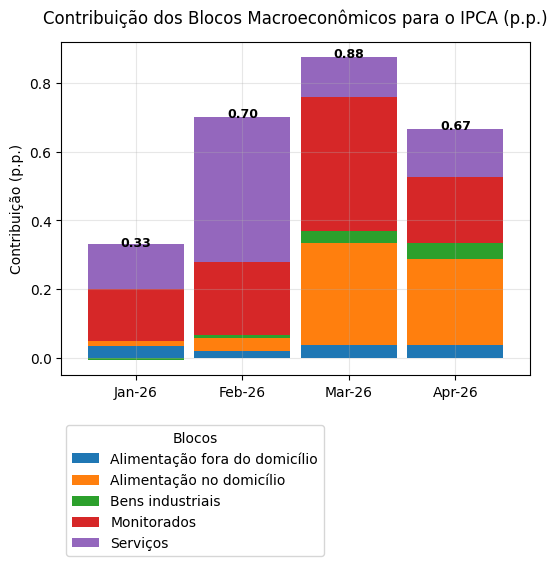

In [456]:
plt.figure(figsize=(5.5, 6))
ax = df_blocos_m.drop(columns="Total").plot(kind="bar", stacked=True, ax=plt.gca(), width=0.9)

plt.title("Contribuição dos Blocos Macroeconômicos para o IPCA (p.p.)", y=1.03)
plt.xlabel("")
plt.ylabel("Contribuição (p.p.)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=0)

# Legenda fora do gráfico, à direita
plt.legend(title="Blocos",
    bbox_to_anchor=(1.02, 1),   # desloca para fora
    loc="upper left",           # ancora no canto superior esquerdo da caixa
    borderaxespad=0)

# Adicionar o total acima de cada barra
for i, total in enumerate(df_blocos_m["Total"]):
    ax.text(
        i,                      # posição x
        total - 0.01,           # posição y (um pouco acima da barra)
        f"{total:.2f}",         # formato do número
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )
# Legenda fora do gráfico
plt.legend(
    title="Blocos",
    bbox_to_anchor=(0.01, -0.15),
    loc="upper left",
    borderaxespad=0
)
plt.tight_layout()
plt.savefig("../pics/blocos.png", transparent=True)
plt.show()

In [ ]:
item_df =   ( df[df["date"] >= "2026-01-01"]
                .assign(date_fmt=lambda x: x["date"].dt.strftime("%b-%y"))
                .groupby(["date_fmt", "bloco_macro", "idItens", "itens"])["ipcaItensCheio"]
                .first()
                .reset_index()
            )
df_item =   (item_df
                .pivot(index=["bloco_macro", "idItens", "itens"],
                       columns="date_fmt", 
                       values="ipcaItensCheio")
            )
df_item =   df_item.reindex(
                sorted(df_item.columns,key=lambda x: pd.to_datetime(x, format="mixed")),
                axis=1
            )
df_item["Acumulado"] = df_item.sum(axis=1).round(4)
df_item = df_item.reset_index()
df_item.columns.name = None
df_item_10 = df_item.sort_values("Acumulado", ascending=False).head(10)
df_item_10

,bloco_macro,idItens,itens,Jan-26,Feb-26,Mar-26,Apr-26,Acumulado
3,Alimentação no domicílio,1103,"Tubérculos, raízes e legumes",7.6300,0.0600,16.7800,8.4500,32.9200
5,Alimentação no domicílio,1105,Hortaliças e verduras,5.2300,3.9000,2.1900,2.7300,14.0500
11,Alimentação no domicílio,1111,Leites e derivados,-2.3100,0.6800,4.2600,5.9500,8.5800
26,Bens industriais,4301,Joias e bijuterias,2.2100,2.8200,1.8400,1.2200,8.0900
35,Monitorados,5104,Combustíveis (veículos),2.1400,-0.4700,4.4700,1.8000,7.9400
47,Serviços,8101,Cursos regulares,0.0000,6.2000,0.0000,0.0000,6.2000
8,Alimentação no domicílio,1108,Pescados,2.7700,0.1100,1.8900,0.9900,5.7600
7,Alimentação no domicílio,1107,Carnes,0.8400,0.5800,1.7300,1.5900,4.7400
21,Bens industriais,3202,"Tv, som e informática",0.8900,1.0200,1.9300,0.8400,4.6800
1,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",-1.2700,0.1300,2.7800,2.5700,4.2100


In [453]:
dfi.export(df_subitem_10.head(20), "../pics/df_subitem_10.png", table_conversion="matplotlib")

In [449]:
subitem_df =   ( df[df["date"] >= "2026-01-01"]
                .assign(date_fmt=lambda x: x["date"].dt.strftime("%b-%y"))
                .groupby(["date_fmt", "bloco_macro", "idSubItens", "subItens"])["ipcaSubItensCheio"]
                .first()
                .reset_index()
            )
df_subitem =   (subitem_df
                .pivot(index=["bloco_macro", "idSubItens", "subItens"],
                       columns="date_fmt", 
                       values="ipcaSubItensCheio")
            )
df_subitem =   df_subitem.reindex(
                sorted(df_subitem.columns,key=lambda x: pd.to_datetime(x, format="mixed")),
                axis=1
            )
df_subitem["Acumulado"] = df_subitem.sum(axis=1).round(4)
df_subitem = df_subitem.reset_index()
df_subitem.columns.name = None
df_subitem_10 = df_subitem.sort_values("Acumulado", ascending=False).head(10)
df_subitem_10


,bloco_macro,idSubItens,subItens,Jan-26,Feb-26,Mar-26,Apr-26,Acumulado
32,Alimentação no domicílio,1103044,Cenoura,9.9400,0.5800,28.0800,26.6300,65.2300
139,Alimentação no domicílio,1114004,Açaí (emulsão),4.2900,25.2900,12.5600,6.9500,49.0900
30,Alimentação no domicílio,1103028,Tomate,20.5200,0.3000,20.3100,6.1300,47.2600
28,Alimentação no domicílio,1103025,Pepino,28.8200,2.4800,4.1200,8.1100,43.5300
27,Alimentação no domicílio,1103020,Abobrinha,13.7700,4.5100,23.5600,-7.3600,34.4800
13,Alimentação no domicílio,1101073,Feijão - carioca (rajado),-0.6400,11.7300,15.4000,3.4700,29.9600
45,Alimentação no domicílio,1105010,Repolho,1.7300,7.7700,6.8900,10.3200,26.7100
31,Alimentação no domicílio,1103043,Cebola,-0.2100,-2.5200,17.2500,11.7600,26.2800
67,Alimentação no domicílio,1106051,Morango,5.0700,-0.8400,1.7500,17.3500,23.3300
120,Alimentação no domicílio,1111004,Leite longa vida,-5.5900,1.2400,11.7400,13.6600,21.0500


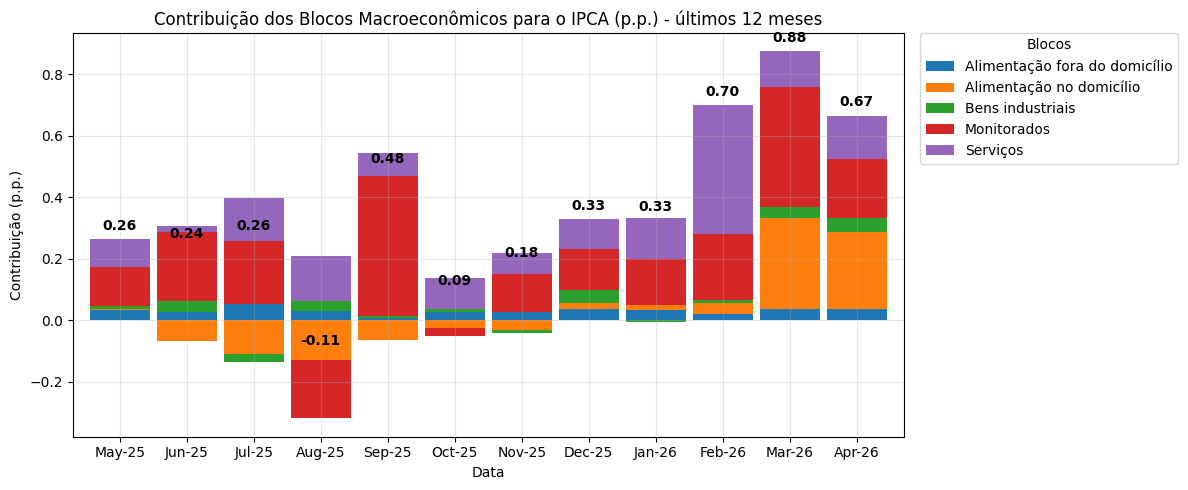

In [ ]:
m = 12

df_blocos.index = pd.to_datetime(df_blocos.index)
df_blocos_m = df_blocos[df_blocos.index >= df_blocos.index.max() - pd.DateOffset(months=m-1)]
df_blocos_m.index = df_blocos_m.index.strftime("%b-%y")
df_blocos_m["Total"] = df_blocos_m.sum(axis=1)

plt.figure(figsize=(12, 5))
ax = df_blocos_m.drop(columns="Total").plot(kind="bar", stacked=True, ax=plt.gca(), width=0.9)

plt.title(f"Contribuição dos Blocos Macroeconômicos para o IPCA (p.p.) - últimos {m} meses")
plt.xlabel("Data")
plt.ylabel("Contribuição (p.p.)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=0)

# Legenda fora do gráfico, à direita
plt.legend(title="Blocos",
    bbox_to_anchor=(1.02, 1),   # desloca para fora
    loc="upper left",           # ancora no canto superior esquerdo da caixa
    borderaxespad=0)

# Adicionar o total acima de cada barra
for i, total in enumerate(df_blocos_m["Total"]):
    ax.text(
        i,                      # posição x
        total + 0.02,           # posição y (um pouco acima da barra)
        f"{total:.2f}",         # formato do número
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )
# Legenda fora do gráfico
plt.legend(
    title="Blocos",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0
)

plt.tight_layout()
#plt.savefig("../pics/blocos_12m.png", transparent=True)
plt.show()

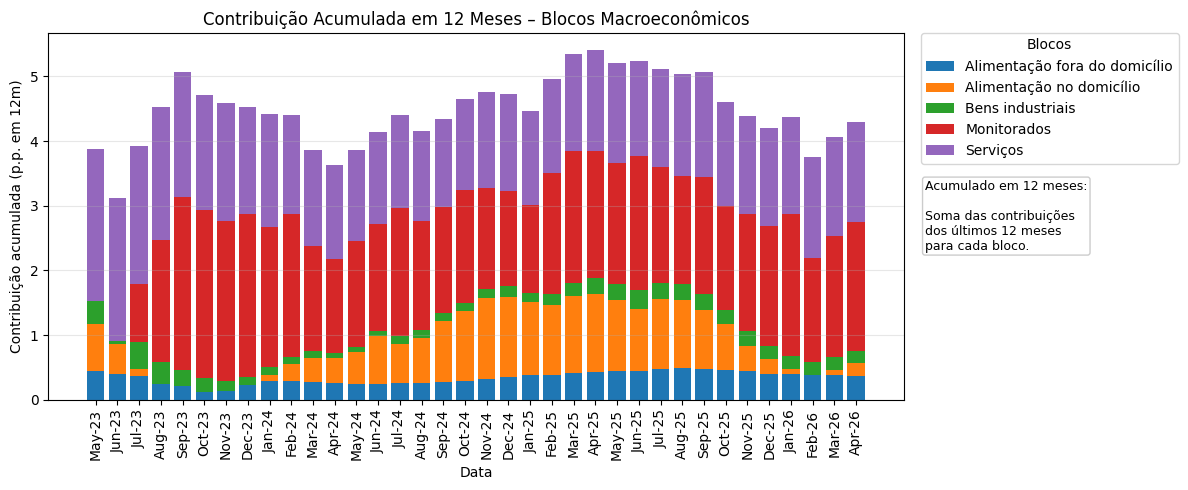

In [ ]:
m = 36

df_blocos_12m.index = pd.to_datetime(df_blocos_12m.index)
df_blocos_12m_m = df_blocos_12m[df_blocos_12m.index >= df_blocos_12m.index.max() - pd.DateOffset(months=m-1)]
df_blocos_12m_m.index = df_blocos_12m_m.index.strftime("%b-%y")

plt.figure(figsize=(12, 5))

# Inicializa o acumulador para empilhar as barras
bottom = np.zeros(len(df_blocos_12m_m))

for col in df_blocos_12m_m.columns:
    plt.bar(
        df_blocos_12m_m.index,
        df_blocos_12m_m[col],
        bottom=bottom,
        label=col
    )
    bottom += df_blocos_12m_m[col].values

plt.title(f"Contribuição Acumulada em 12 Meses – Blocos Macroeconômicos")
plt.xlabel("Data")
plt.ylabel("Contribuição acumulada (p.p. em 12m)")
plt.grid(True, axis="y", alpha=0.3)
# Legenda fora do gráfico
plt.legend(
    title="Blocos",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0
)
# 🔵 Caixa explicativa abaixo da legenda
plt.text(
    1.025, 0.60,  # posição relativa (x, y) no eixo da figura
    "Acumulado em 12 meses:\n\n"
    "Soma das contribuições\n"
    "dos últimos 12 meses\n"
    "para cada bloco.",
    transform=plt.gca().transAxes,
    fontsize=9,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.2",
        facecolor="#ffffff",
        edgecolor="gray",
        alpha=0.4
    )
)
plt.xticks(rotation=90)
plt.tight_layout()
#plt.savefig("../pics/blocos_acum_12m.png", transparent=True)
plt.show()
